# Step 10: is late green-up on high ground fooling the April map?

**Where we are:** in Step 9, two leaf-season fixes painted false alarms along the mountain ridges.

**The guess:** higher ground greens up later in spring. On April 12 the ridges had not leafed out yet, so "greened up less than normal" looked like a burn.

**The plan, written down before looking at any result:**
- **Test 1:** on *unburned* land, does the April change climb steadily with height?
- **Test 2:** is fix A's false-alarm rate higher on high ground?
- **A rival explanation:** the way a slope faces. The sun was higher in April than in March, which changes how shaded slopes look.
- **Fix C:** look-alike groups by burn score before the fire *and* height (10 score groups x 5 height bands), with the same rule as before: burned = the score fell 0.10 more than normal.

New words:
- **DEM (digital elevation model):** a map where each pixel holds the height of the ground. Ours is NASA's NASADEM, 30 m pixels, measured by radar from the Space Shuttle in 2000.
- **False-alarm rate:** of the pixels that did *not* burn, the share a map flagged anyway.

**Honest warning:** fix C was designed after seeing where the mistakes were, so the official outline is not a perfectly fresh exam for it.

In [1]:
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path('..') / 'src'))
import numpy as np
import pandas as pd
import hls, fires, terrain
step10 = importlib.import_module('10_ridge_check')  # reuse the script's functions
# The script saves pictures to files only. This line also shows them here in the notebook.
%matplotlib inline
hls.login();

## Get the height of every pixel, then run the tests
The height map is downloaded once into `data/dem/` and lined up with the photo's pixel grid.

In [2]:
out = step10.run()
r, height = out['r'], out['height']
print(f"Height in the box: {np.nanmin(height):.0f} to {np.nanmax(height):.0f} m")
print(f"Typical height inside the outline: {np.median(height[r['inside']]):.0f} m")
print(f"Typical height of unburned land:   {np.median(height[out['unburned']]):.0f} m")

Height in the box: 260 to 979 m
Typical height inside the outline: 504 m
Typical height of unburned land:   588 m


The burn sits *lower* than the land around it. So the unburned neighbors of this fire are mostly higher ground.

## Test 1: does unburned land green up less the higher it sits?
Unburned = outside the official outline and more than 300 m from it. The land is split into 10 height bands with the same number of pixels each. The three extra columns split it by kind of land, so we do not confuse "high ground" with "a different kind of plant".

In [3]:
out['by_height_change'].round(3)

,height band,height (m),all unburned land,"low score before (bare, leafless)",middle score before,high score before (evergreen)
0,1,312.593,-0.184,-0.224,-0.230,-0.133
1,2,334.615,-0.192,-0.259,-0.251,-0.127
2,3,355.091,-0.225,-0.415,-0.285,-0.148
3,4,427.902,-0.376,-0.453,-0.320,-0.187
4,5,555.546,-0.193,-0.299,-0.151,-0.039
5,6,610.073,-0.123,-0.191,-0.125,-0.057
6,7,645.786,-0.121,-0.166,-0.131,-0.074
7,8,670.845,-0.159,-0.162,-0.170,-0.144
8,9,715.615,-0.094,-0.110,-0.100,-0.073
9,10,816.063,-0.061,-0.065,-0.070,-0.050


## Test 2: where are fix A's false alarms?

In [4]:
out['fa_height'].round(3)

,height band,false alarm rate
0,275-343 m,0.025
1,343-499 m,0.009
2,499-629 m,0.137
3,629-687 m,0.144
4,687-979 m,0.439


In [5]:
out['fa_facing'].round(3)

,slope faces,false alarm rate
0,north,0.110
1,east,0.208
2,south,0.256
3,west,0.228


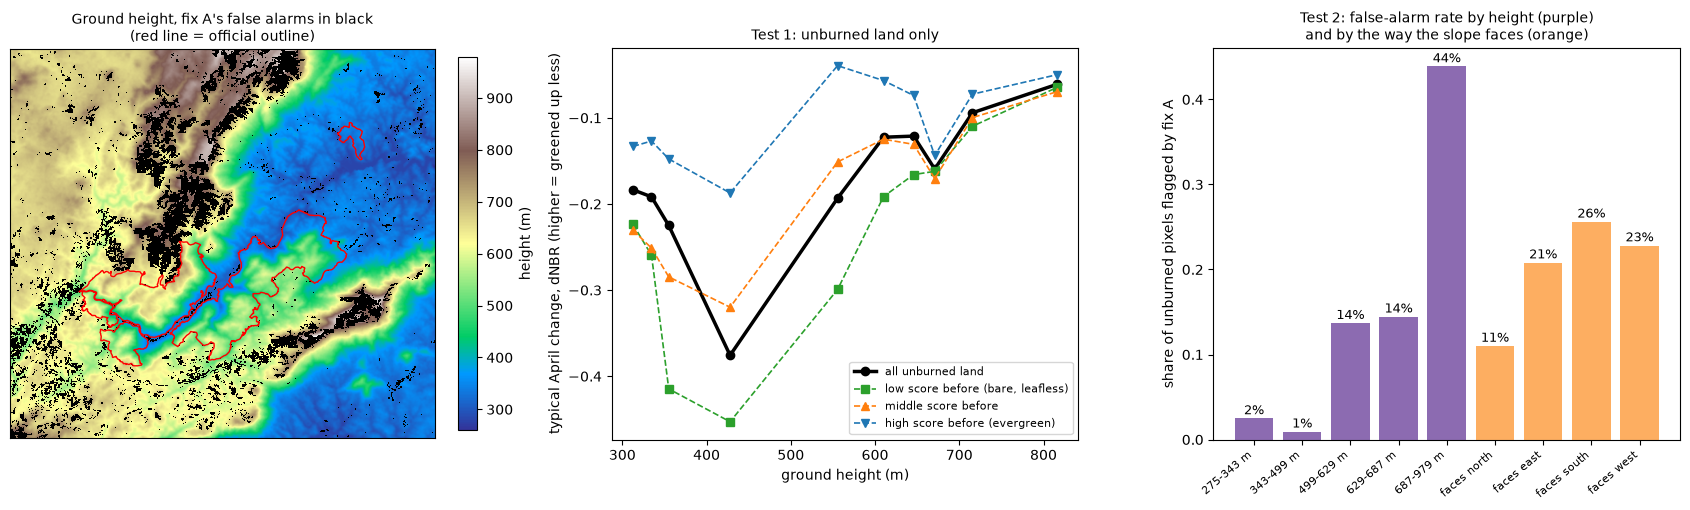

In [6]:
step10.plot_checks(height, r, out['by_height_change'], out['fa_height'], out['fa_facing'],
                   '../figures/10_ridge_check.png');

**What the tests say**
- **Test 2 backs the guess strongly.** On the highest ground, fix A flagged 44% of unburned pixels. Below 500 m it flagged 1 to 2%. In the left picture the false alarms (black) sit on the high brown plateau.
- **Test 1 backs it, with a wrinkle.** From about 430 m upward, the higher the ground, the less it greened up (the black line climbs from -0.38 to -0.06). Below 430 m the pattern reverses, so it is not one simple straight line. All three kinds of land show the same shape, so this is not just a different kind of plant.
- **The rival is not ruled out.** North-facing slopes got about half as many false alarms as the others. The way a slope faces matters too, but much less than height.

## Fix C: look-alikes with the same score before the fire AND the same height

In [7]:
print('Smallest look-alike group (pixels):', out['smallest_group'])
out['scores']

Smallest look-alike group (pixels): {'April': 1542, 'March 26': 2314}


,pair,map,flagged km2,caught,right,F1,false alarms km2,overall accuracy
0,April,textbook,4.4,0.157,0.993,0.272,0.0,0.907
1,April,histogram,7.7,0.262,0.939,0.409,0.5,0.917
2,April,fix A: look-alikes,45.3,0.422,0.257,0.320,33.6,0.803
3,April,fix B: ring,31.0,0.366,0.325,0.344,21.0,0.847
4,April,fix C: look-alikes + height,29.8,0.522,0.484,0.502,15.4,0.886
5,March 26,textbook,19.8,0.613,0.958,0.747,0.8,0.959
6,March 26,histogram,26.9,0.728,0.839,0.779,4.3,0.960
7,March 26,fix A: look-alikes,21.2,0.646,0.944,0.767,1.2,0.962
8,March 26,fix B: ring,21.0,0.641,0.945,0.764,1.1,0.961
9,March 26,fix C: look-alikes + height,21.1,0.644,0.944,0.766,1.2,0.961


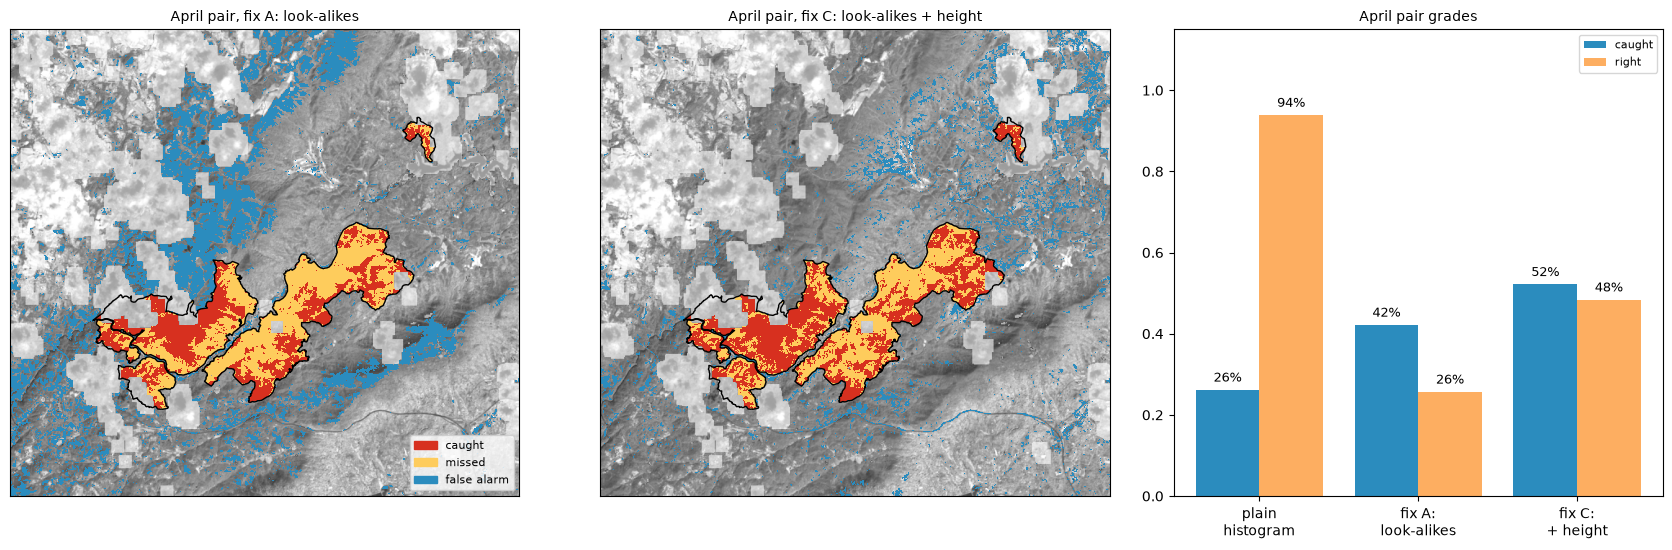

In [8]:
step10.plot_fix_c(r, out['scores'], '../figures/10_fix_c.png');

## What we learned
- **The guess holds.** Late green-up on high ground explains most of the false alarms. This is now measured, not guessed.
- **Fix C is the best April map.** "Right" went from 26% to 48% and "caught" from 42% to 52% (F1 0.50, up from 0.41 for the plain histogram map). The big ridge patches are gone; scattered speckle remains.
- **It is still far behind the March 26 map** (caught 73%, right 84%). Half of fix C's flags are still wrong.
- **On the March 26 pair, fix C changes nothing,** as expected: nothing had greened up yet.
- **Timing still beats method.** But when the only clear photo is a late one, knowing the height of the ground gets back about half of what the leaf season took away.

## Limits
- **Not a fresh exam.** Fix C was designed after looking at where fix A failed against the outline.
- **One fire, one pair of dates.** Whether "compare with look-alikes at the same height" helps elsewhere is untested.
- **The way a slope faces is not handled.** It showed a smaller effect and is a clear next thing to try.
- **Below about 430 m the height pattern reverses,** and I have not explained why.